In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve, average_precision_score
)

RANDOM_STATE = 42
DATA_PATH = Path("Water Quality.csv")
TARGET_NAME = "Specific conductance"

print("Working directory:", Path.cwd())
print("Dataset expected at:", DATA_PATH.resolve())

Working directory: c:\Users\YASH\Desktop\BrainyBeam\daily task
Dataset expected at: C:\Users\YASH\Desktop\BrainyBeam\daily task\Water Quality.csv


In [ ]:
# If the CSV is elsewhere, change DATA_PATH to its full path.
if not DATA_PATH.exists():
    candidates = list(Path.cwd().glob("*.csv"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
        print("Using detected CSV:", DATA_PATH)
    else:
        raise FileNotFoundError(
            f"Cannot find {DATA_PATH}. Put Water Quality.csv beside this notebook "
            "or set DATA_PATH to the full CSV path."
        )

raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)
display(raw.head())
print("\nColumns:")
print(raw.columns.tolist())

Raw shape: (229916, 40)


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,...,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN



Columns:
['DatasetName', 'MonitoringLocationID', 'MonitoringLocationName', 'MonitoringLocationLatitude', 'MonitoringLocationLongitude', 'MonitoringLocationHorizontalCoordinateReferenceSystem', 'MonitoringLocationHorizontalAccuracyMeasure', 'MonitoringLocationHorizontalAccuracyUnit', 'MonitoringLocationVerticalMeasure', 'MonitoringLocationVerticalUnit', 'MonitoringLocationType', 'ActivityType', 'ActivityMediaName', 'ActivityStartDate', 'ActivityStartTime', 'ActivityEndDate', 'ActivityEndTime', 'ActivityDepthHeightMeasure', 'ActivityDepthHeightUnit', 'SampleCollectionEquipmentName', 'CharacteristicName', 'MethodSpeciation', 'ResultSampleFraction', 'ResultValue', 'ResultUnit', 'ResultValueType', 'ResultDetectionCondition', 'ResultDetectionQuantitationLimitMeasure', 'ResultDetectionQuantitationLimitUnit', 'ResultDetectionQuantitationLimitType', 'ResultStatusID', 'ResultComment', 'ResultAnalyticalMethodID', 'ResultAnalyticalMethodContext', 'ResultAnalyticalMethodName', 'AnalysisStartDate',

In [5]:
required = {"CharacteristicName", "ResultValue"}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Missing required columns for this dataset format: {missing}")

df = raw.copy()
df["CharacteristicName"] = df["CharacteristicName"].astype(str).str.strip()
df["ResultValue"] = pd.to_numeric(df["ResultValue"], errors="coerce")

# Build a sample key from available location/date fields.
key_candidates = ["MonitoringLocationID", "ActivityStartDate"]
keys = [c for c in key_candidates if c in df.columns]
if not keys:
    raise ValueError("Expected MonitoringLocationID and/or ActivityStartDate to identify samples.")

if "ActivityStartDate" in df.columns:
    df["ActivityStartDate"] = pd.to_datetime(df["ActivityStartDate"], errors="coerce")

# Use location + date when both exist; otherwise use available key(s).
df = df.dropna(subset=["ResultValue"])
if "ActivityStartDate" in keys:
    df = df.dropna(subset=["ActivityStartDate"])

# Keep numeric measurement parameters. Exclude IDs, dates, and metadata from the pivot.
# Each parameter becomes a feature column; repeated readings are averaged.
wide = df.pivot_table(
    index=keys,
    columns="CharacteristicName",
    values="ResultValue",
    aggfunc="mean"
).reset_index()
wide.columns.name = None

print("Pivoted sample table shape:", wide.shape)
display(wide.head())

Pivoted sample table shape: (7283, 85)


,MonitoringLocationID,ActivityStartDate,"Alkalinity, total",Aluminum,Ammonia,Antimony,Apparent color,Arsenic,Barium,Beryllium,...,True color,Tungsten,Turbidity,Uranium,Vanadium,Ytterbium,Yttrium,Zinc,Zirconium,pH
0,NB01BR0006,2000-09-22,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NB01BR0006,2000-10-11,NaN,NaN,NaN,NaN,274.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NB01BR0006,2000-11-23,NaN,NaN,NaN,NaN,215.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NB01BR0006,2001-04-26,1.8,NaN,NaN,NaN,158.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.9
4,NB01BR0006,2001-05-22,2.8,NaN,NaN,NaN,315.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.1


In [6]:
# Normalize names for robust matching, but preserve original column names.
def find_column_by_phrase(columns, phrase):
    phrase = phrase.casefold()
    matches = [c for c in columns if phrase in str(c).casefold()]
    return matches[0] if matches else None

target_col = find_column_by_phrase(wide.columns, TARGET_NAME)
if target_col is None:
    print("Could not find exact phrase 'Specific conductance'. Available measurement columns include:")
    print([c for c in wide.columns if c not in keys][:50])
    raise ValueError(
        "Specific conductance target not found. Update TARGET_NAME to a numeric characteristic "
        "that exists in your dataset."
    )

# Avoid obvious target leakage from conductivity aliases and the target itself.
metadata_cols = set(keys)
leakage_terms = ("conductivity", "specific conductance")
feature_cols = [
    c for c in wide.columns
    if c not in metadata_cols
    and c != target_col
    and not any(term in str(c).casefold() for term in leakage_terms)
    and pd.api.types.is_numeric_dtype(wide[c])
]

# Require enough observations for training/evaluation.
model_df = wide[[*keys, target_col, *feature_cols]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=[target_col])
# Remove all-empty and constant features.
feature_cols = [
    c for c in feature_cols
    if model_df[c].notna().any() and model_df[c].nunique(dropna=True) > 1
]
if len(feature_cols) == 0:
    raise ValueError("No usable numeric predictor columns remain after leakage filtering.")

X = model_df[feature_cols].copy()
y = pd.to_numeric(model_df[target_col], errors="coerce")
valid = y.notna()
X, y, model_df = X.loc[valid], y.loc[valid], model_df.loc[valid]

print("Target column:", target_col)
print("Rows:", len(X), "| Numeric predictors:", len(feature_cols))
print("Target summary:")
display(y.describe())
print("Feature columns:")
print(feature_cols)

Target column: Specific conductance
Rows: 7222 | Numeric predictors: 79
Target summary:


count    7222.000000
mean       73.722480
std       130.236149
min         5.130000
25%        25.000000
50%        30.600000
75%        42.637500
max      3255.000000
Name: Specific conductance, dtype: float64

Feature columns:
['Alkalinity, total', 'Aluminum', 'Ammonia', 'Antimony', 'Apparent color', 'Arsenic', 'Barium', 'Beryllium', 'Bismuth', 'Boron', 'Bromine', 'Cadmium', 'Calcium', 'Cerium', 'Cesium', 'Chloride', 'Chlorophyll a, uncorrected for pheophytin', 'Chromium', 'Cobalt', 'Copper', 'Dissolved oxygen (DO)', 'Dissolved oxygen saturation', 'Europium', 'Fecal Coliform', 'Fluoride', 'Gadolinium', 'Gallium', 'Germanium', 'Gran acid neutralizing capacity', 'Hardness, carbonate', 'Holmium', 'Inorganic carbon', 'Inorganic nitrogen (nitrate and nitrite)', 'Iron', 'Lanthanum', 'Lead', 'Lithium', 'Lutetium', 'Magnesium', 'Manganese', 'Mercury', 'Molybdenum', 'Neodymium', 'Nickel', 'Niobium', 'Nitrate', 'Nitrite', 'Organic carbon', 'Orthophosphate', 'Potassium', 'Praseodymium', 'Rubidium', 'Samarium', 'Scandium', 'Selenium', 'Silicate', 'Silver', 'Sodium', 'Strontium', 'Sulfate', 'Suspended Sediment Concentration (SSC)', 'Temperature, air', 'Temperature, water', 'Terbium', 'Thallium', 'Tin', '

In [7]:
# If date is present, use a chronological holdout; otherwise use a seeded random split.
if "ActivityStartDate" in model_df.columns:
    order = model_df["ActivityStartDate"].sort_values().index
    cut = int(len(order) * 0.80)
    train_idx, test_idx = order[:cut], order[cut:]
    # Ensure no empty split for small datasets.
    if len(train_idx) == 0 or len(test_idx) == 0:
        train_idx, test_idx = train_test_split(
            model_df.index, test_size=0.20, random_state=RANDOM_STATE
        )
else:
    train_idx, test_idx = train_test_split(
        model_df.index, test_size=0.20, random_state=RANDOM_STATE
    )

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 5777 | Test rows: 1445


Regression metrics: {'MAE': 8.033091129565559, 'RMSE': 38.47412658222477, 'R2': 0.9428554975821531}


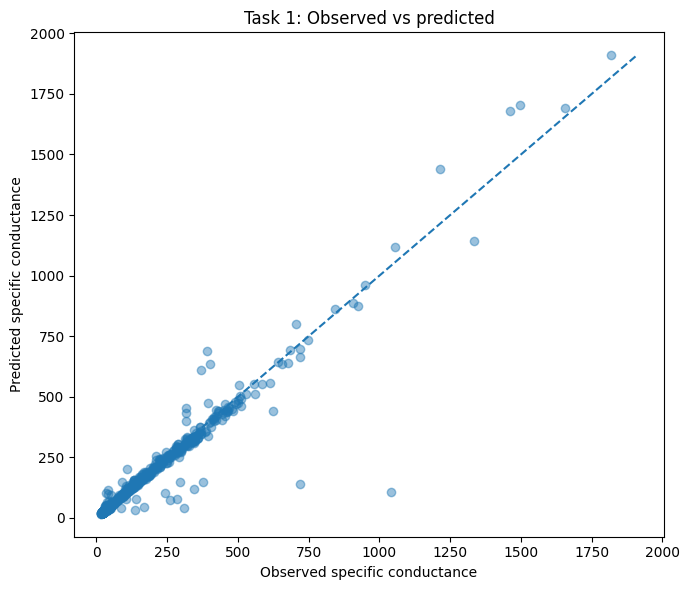

In [8]:
regression_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
regression_model.fit(X_train, y_train)
y_pred_reg = regression_model.predict(X_test)

reg_metrics = {
    "MAE": mean_absolute_error(y_test, y_pred_reg),
    "RMSE": mean_squared_error(y_test, y_pred_reg) ** 0.5,
    "R2": r2_score(y_test, y_pred_reg)
}
print("Regression metrics:", reg_metrics)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_reg, alpha=0.45)
lims = [
    min(float(np.nanmin(y_test)), float(np.nanmin(y_pred_reg))),
    max(float(np.nanmax(y_test)), float(np.nanmax(y_pred_reg)))
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Observed specific conductance")
plt.ylabel("Predicted specific conductance")
plt.title("Task 1: Observed vs predicted")
plt.tight_layout()
plt.show()